# 01 — 建 panel（Panel build）

这个 notebook 把 raw rank panel 变成研究用的 panel stack：

- `rank`：date × commodity × rank，带真实合约和 flags。
- `contract`：date × real contract，每张合约完整的一生和 expiry proxy。
- `returns`：contract-level returns，再映射回 rank slot。
- `pairs`：每天/每个商品选出的最近两个 eligible 合约。
- `spread`：主 pair 的 dollar/log/percentage spread。
- `universe`：trailing liquidity 和 threshold booleans（不应用）。
- `episodes`：固定合约对的一段 episode，含 entry/exit spread。
- `adjacent_pairs` / `adjacent_spread`：所有 eligible adjacent pair，做 robustness。

所有逻辑在 `src/`；notebook 只负责叙述和保存。


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))


In [2]:
import pandas as pd

from src import config, qa, viz
from src.load import load_rank_panel
from src.panel import build_all, liquidity_summary, save_panel

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


## 1. 建整个 stack

Eligibility 锁定为：**不持有进入交割月的合约 + 交割月开始前至少 5 个 session 退出
+ `days_to_last_trading > 10`**。`D=5/20` 可以传给 `build_all` 做稳健性；主结果用默认值。


In [3]:
rank = load_rank_panel()
panels = build_all(rank)
{k: frame.shape for k, frame in panels.items()}


{'rank': (1013664, 23),
 'contract': (950626, 29),
 'returns': (1013664, 24),
 'pairs': (236186, 29),
 'spread': (236186, 30),
 'universe': (236186, 56),
 'episodes': (6664, 17),
 'adjacent_pairs': (610801, 29),
 'adjacent_spread': (610801, 30)}

## 2. Rank panel

Rank panel 保留 raw market fields，并加上真实 contract identity、`is_roll`、
`stale`、missing flags 和解析结果。


In [4]:
rank_panel = panels["rank"]
rank_panel[["date", "root", "rank", "contract_code", "settle", "is_roll"]].head(3)


,date,root,rank,contract_code,settle,is_roll
0,1986-01-02,BO,1,BOF86,21.62,False
1,1986-01-02,BO,2,BOH86,21.96,False
2,1986-01-02,BO,3,BOK86,22.20,False


## 3. Contract panel

每张真实合约有一条连续的生命，rank 从 4 → 3 → 2 → 1。
`last_trade_proxy` 是这张合约在 extract 里最后一次出现的日期；
`days_to_last_trading` 按 trading session 计。


In [5]:
contract = panels["contract"]
print(f"{len(contract):,} contract-date rows; {contract['contract_key'].nunique():,} contracts")
contract[contract["contract_key"].eq("CL_CLK20")].tail(8)[
    ["date", "rank", "settle", "last_trade_proxy", "days_to_last_trading", "in_delivery_month"]
]


950,626 contract-date rows; 6,735 contracts


,date,rank,settle,last_trade_proxy,days_to_last_trading,in_delivery_month
796608,2020-04-09,1,22.76,2020-04-21,7,False
796704,2020-04-13,1,22.41,2020-04-21,6,False
796800,2020-04-14,1,20.11,2020-04-21,5,False
796896,2020-04-15,1,19.87,2020-04-21,4,False
796992,2020-04-16,1,19.87,2020-04-21,3,False
797088,2020-04-17,1,18.27,2020-04-21,2,False
797184,2020-04-20,1,-37.63,2020-04-21,1,False
797280,2020-04-21,1,10.01,2020-04-21,0,False


## 4. Return panel：换月日用新合约

2020-04-22 WTI 从 CLK20 换到 CLM20。正确的 rank-1 return 用 CLM20 前一天的价格
（11.57，当时它是 M2），不是 CLK20 的 10.01。`ret_rank` 和 `ret_naive` 的差
就是 roll gap，不是收益。


In [6]:
returns = panels["returns"]
returns[(returns["root"].eq("CL")) & (returns["rank"].eq(1)) & returns["date"].between("2020-04-17", "2020-04-23")][
    ["date", "contract_code", "settle", "ret_rank", "ret_naive"]
]


,date,contract_code,settle,ret_rank,ret_naive
852012,2020-04-17,CLK20,18.27,-0.080523,-0.080523
852108,2020-04-20,CLK20,-37.63,-3.059661,-3.059661
852204,2020-04-21,CLK20,10.01,-1.266011,-1.266011
852300,2020-04-22,CLM20,13.78,0.191011,0.376623
852396,2020-04-23,CLM20,16.50,0.197388,0.197388


In [7]:
qa.assert_unique_contract_date(contract)
qa.assert_rank_monotonic(rank_panel)
qa.assert_roll_sync(rank_panel)
qa.assert_return_mapping(returns)
qa.assert_contract_calendar(contract)
qa.assert_pair_adjacency(panels["pairs"])
print("all panel invariants passed")


all panel invariants passed


## 5. Pair episodes 和 spread

主 pair 是“最近两个 eligible 且相邻的合约”。接近 delivery buffer 时会从 M1–M2
切到 M2–M3；下面是 pair mix。

`pairs`/`spread` 是**主 pair**；`adjacent_pairs`/`adjacent_spread` 保留所有
eligible adjacent pair，做 robustness/alternative analysis；`is_main_pair` 标记主 subset。


In [8]:
pairs = panels["pairs"]
pairs["pair_rank_mix"].value_counts()


pair_rank_mix
M1-M2    139017
M2-M3     97169
Name: count, dtype: int64

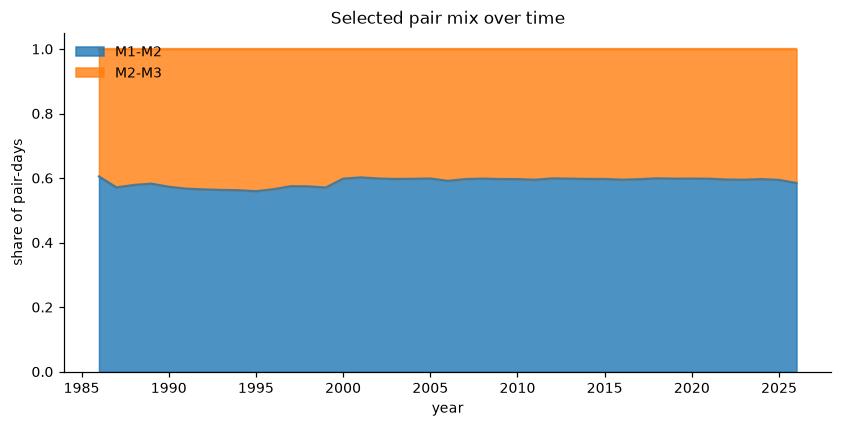

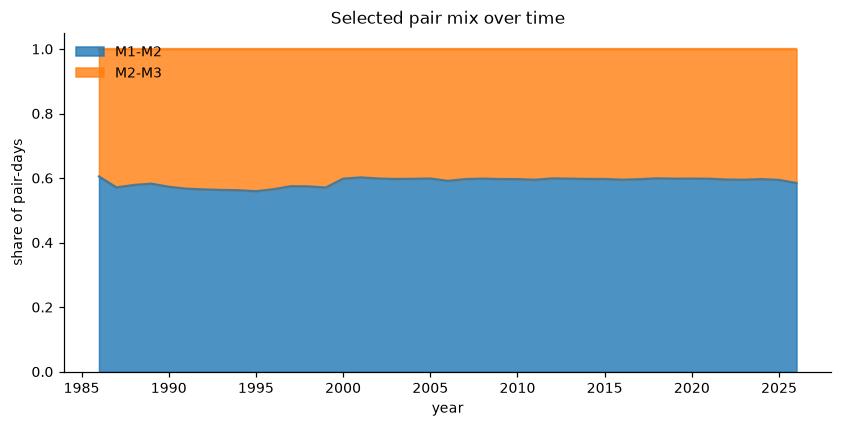

In [9]:
viz.plot_pair_mix(pairs)


In [10]:
episodes = panels["episodes"]
print(f"{len(episodes):,} episodes")
episodes.head(5)


6,664 episodes


,root,episode_id,contract_near,contract_far,pair_rank_mix,entry_date,exit_date,holding_days,n_obs,entry_spread,exit_spread,mean_spread,mean_liq_volume,min_liq_volume,mean_liq_oi,min_liq_oi,spread_change
0,BO,BO_0001,BOH86,BOK86,M2-M3,1986-01-02,1986-02-24,37,37,-0.24,-0.39,-0.382703,NaN,NaN,NaN,NaN,-0.15
1,BO,BO_0002,BOK86,BON86,M2-M3,1986-02-25,1986-04-24,42,42,-0.34,-0.32,-0.331905,1526.075000,1400.5,9169.425000,8649.5,0.02
2,BO,BO_0003,BON86,BOQ86,M2-M3,1986-04-25,1986-06-24,42,42,-0.12,-0.16,-0.141429,568.595238,423.5,5301.821429,4577.0,-0.04
3,BO,BO_0004,BOQ86,BOU86,M2-M3,1986-06-25,1986-07-25,22,22,-0.08,-0.15,-0.147727,420.500000,368.0,4121.590909,4003.0,-0.07
4,BO,BO_0005,BOU86,BOV86,M2-M3,1986-07-28,1986-08-25,21,21,-0.15,-0.10,-0.124286,560.880952,481.0,4856.095238,4250.5,0.05


主 pair 会在 front contract 进入 10-session expiry buffer 时排除它。
CL 的负价格仍然保留在 rank/contract panel 里并被 flag；
如果用那条腿构造 log spread，它无定义；dollar spread 仍然有定义。


In [11]:
spread = panels["spread"]
spread[(spread["root"].eq("CL")) & spread["date"].between("2020-04-17", "2020-04-23")][
    ["date", "contract_near", "contract_far", "spread_dollar", "spread_log", "negative_price"]
]


,date,contract_near,contract_far,spread_dollar,spread_log,negative_price
198177,2020-04-17,CLM20,CLN20,-4.39,-0.161600,False
198201,2020-04-20,CLM20,CLN20,-5.85,-0.251804,False
198225,2020-04-21,CLM20,CLN20,-7.12,-0.479573,False
198249,2020-04-22,CLM20,CLN20,-6.91,-0.406432,False
198273,2020-04-23,CLM20,CLN20,-4.94,-0.261898,False


In [12]:
rank_panel.loc[rank_panel["negative_price"], ["date", "root", "rank", "contract_code", "settle"]]


,date,root,rank,contract_code,settle
852108,2020-04-20,CL,1,CLK20,-37.63


## 6. 流动性 / universe（不应用 threshold）

Universe table 带 contract-level trailing medians、rank-level fallback flags、
pair minimums，以及 1k/5k/10k/20k 的 booleans。这里不删任何 row。
看完 00 的诊断图后再选 threshold。


In [13]:
liquidity_summary(panels["universe"])


,threshold,pair_days,pass_volume_days,pass_oi_days,roots_pass_volume,roots_pass_oi
0,1000,236186,127944,180736,20,24
1,5000,236186,69301,151137,19,21
2,10000,236186,45043,125989,13,20
3,20000,236186,27121,91569,12,20


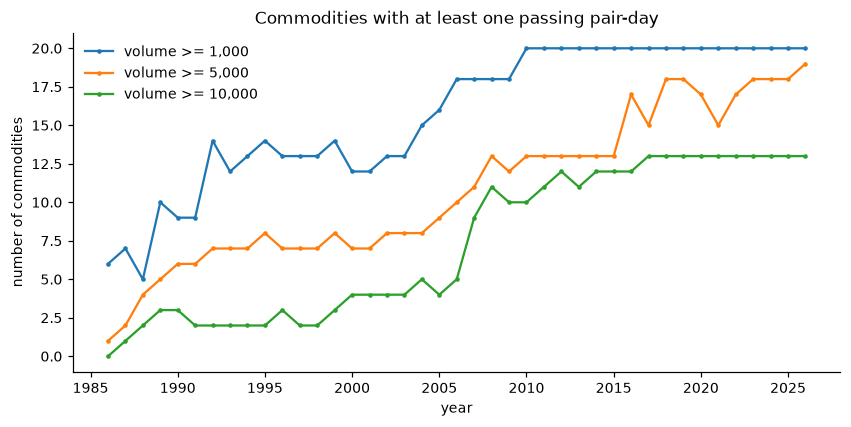

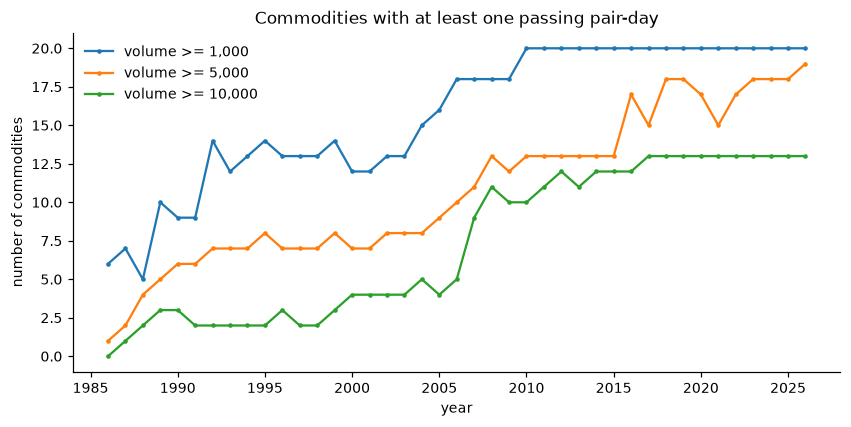

In [14]:
viz.plot_universe_counts(panels["universe"])


## 7. 保存 processed panels

Parquet 写到 `data/processed/`，是 gitignored；随时可以用这个 notebook 重建。


In [15]:
paths = {name: save_panel(frame, name).relative_to(ROOT) for name, frame in panels.items()}
{k: str(v) for k, v in paths.items()}

{'rank': 'data/processed/rank.parquet',
 'contract': 'data/processed/contract.parquet',
 'returns': 'data/processed/returns.parquet',
 'pairs': 'data/processed/pairs.parquet',
 'spread': 'data/processed/spread.parquet',
 'universe': 'data/processed/universe.parquet',
 'episodes': 'data/processed/episodes.parquet',
 'adjacent_pairs': 'data/processed/adjacent_pairs.parquet',
 'adjacent_spread': 'data/processed/adjacent_spread.parquet'}

## 8. 这个 notebook 不做什么

- 不做 signal 定义（A/B/C/D/H）。
- 不做 backtest、cost model、position sizing、最终 liquidity threshold。
- 不做 paper replication。

这些是下一阶段。数据层到这里结束：干净、可验证、可以直接开始研究。
